# ECG condition keys: whole records, selected regions and clusters

KEY-01 · 3 November 2026 · Executed analysis of reused external development data

This notebook asks whether averaging **selected ECG-region embeddings** gives better reference
keys than averaging **whole-record embeddings**. It explains the algorithm, compares prediction
rankings and describes clusters. Four existing annotation groups are examined: myocardial
infarction annotations (MI), ST/T changes (STTC), conduction findings (CD), and hypertrophy
annotations (HYP). An ECG can belong to several groups. These annotations are proxies; the
experiment does not establish a person's disease, screening eligibility or clinical diagnosis.

The prospective protocol was committed before scoring. Its primary endpoint, controls and gates
remain fixed. All values and charts below come from the executed KEY-01 artifacts. No example
patient identifiers, raw waveforms or per-record feature vectors are displayed.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve

ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from ecg_experiment.files import sha256_file

report_path = ROOT / 'reports/condition-keys-2026-11-03/aggregate.json'
result = json.loads(report_path.read_text())
assert result['status'] == 'completed'
artifact_path = ROOT / 'outputs/condition_keys_20261103_v2/artifacts.npz'
assert sha256_file(artifact_path) == result['artifact_sha256'][str(artifact_path.relative_to(ROOT))]
private = np.load(artifact_path, allow_pickle=False)
groups = result['groups']
arms = list(result['metrics'])
names = {
    'whole': 'Whole-record keys',
    'window_whole_keys': 'Region search, whole-record keys',
    'window_selected_keys': 'Selected-region keys',
    'fixed_selected_keys': 'Fixed 1-second region keys',
    'shuffled_keys': 'Permuted condition keys',
}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Study:', result['study'], '| source commit:', result['git_commit'][:12])
print('Scope:', result['scope'], '| CPU seconds:', round(result['wall_seconds'], 2))

Study: KEY-01 | source commit: fb33d1494fca
Scope: reused_external_development | CPU seconds: 148.99


## 1. What the professor's idea means

A key is a reference direction in an embedding space. The encoder turns a recording or region into
a vector. Averaging labeled reference vectors produces a key for that group. A new recording is
ranked by how much its vector resembles that group's key compared with a normal-reference key.

The [2025 No time to train! paper](https://arxiv.org/html/2507.02798v1) combines image-region
proposals with pretrained features and reference prototypes. KEY-01 adapts the reference-matching
idea to native ECG embeddings. **SAM2 and DINOv2 are not run here.** Regions are contiguous
windows of existing xECG tokens, not image masks or physiological P/QRS/T delineations.

```text
Training ECGs -> frozen xECG vectors -> training-only standardization
             -> whole-record keys -> select reference regions once -> region keys

New ECG -> candidate token windows -> similarity to frozen keys -> one score per group
```

Training-free matching still needs labeled references and a pretrained encoder. It cannot create
an averaged key for a condition with no reference examples. Adding a key later is possible without
retraining the encoder, but recognition of an unseen disease category is not tested in this notebook.

## 2. Data and separation of roles

Keys use the unchanged all-age 25,000-record training cohort. Human-read sources supply the
labels. SPH supplies evaluation ECGs and never contributes reference vectors, scaler estimates,
cluster centers or selection rules. All four groups are already represented in the training pool.

The SPH evaluation role is patient-separated from its existing calibration role. Calibration
records are not used here because this is a ranking experiment. SPH has been examined in prior
experiments and is **development data**. No closed Challenge or EchoNext test data are opened.
Source-family Challenge splits are record-based, so their training patient identities are incomplete.
No age subgroup is analysed. The encoder's original pretraining does not establish class-unseen learning.

,records,normal annotations,multiple abnormal groups
role,,,
Reference training,25000,7393,4540
SPH evaluation,10434,6850,311


SPH evaluation patients: 10116


,positive reference ECGs,SPH positive ECGs
MI,2041,118
STTC,12356,2521
CD,6049,1166
HYP,2376,104


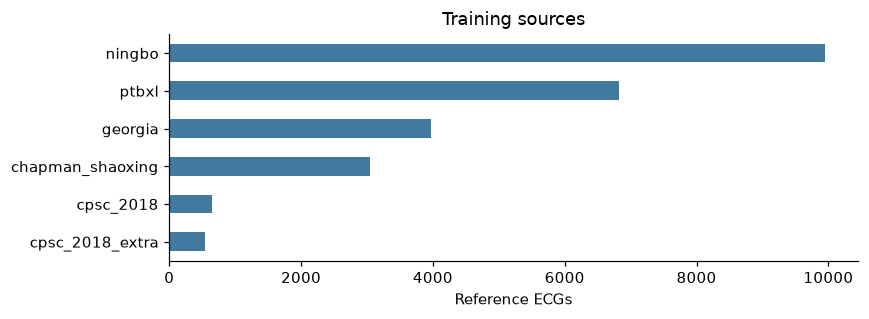

In [2]:
counts = result['counts']
display(pd.DataFrame([
    {'role': 'Reference training', 'records': counts['training'],
     'normal annotations': counts['training_normals'],
     'multiple abnormal groups': counts['training_multiple_groups']},
    {'role': 'SPH evaluation', 'records': counts['query'],
     'normal annotations': counts['query_normals'],
     'multiple abnormal groups': counts['query_multiple_groups']},
]).set_index('role'))
print('SPH evaluation patients:', counts['query_patients'])
support_counts = pd.DataFrame({'positive reference ECGs': counts['training_positive']})
support_counts['SPH positive ECGs'] = [
    result['metrics']['whole']['groups'][g]['positives'] for g in support_counts.index
]
display(support_counts)
source_counts = pd.Series(counts['training_sources']).sort_values()
source_counts.plot.barh(figsize=(8, 3), color='#427a9f', xlabel='Reference ECGs', title='Training sources')
plt.tight_layout()
plt.show()

## 3. Integrity before new scores

Every directly used input is checked against predecessor receipt hashes. The saved HEADS-01
SPH prediction metrics are recomputed exactly, without refitting its models. Separately, averaging
the 40 float16 cached tokens must reproduce the saved float32 pooled vector to relative L2 error
at most 0.001. That second test qualifies pooling semantics at cache precision; it does not imply
bit-identical embeddings. A mismatch stops the experiment rather than silently dropping records.
The first attempt stopped before scoring because it could not parse decimal membership strings.
The committed v2 execution correction validates those strings as exact numeric zero/one values;
the scientific comparison and cohort identities are unchanged and the failed attempt is preserved.

Earlier local visual/native reference-matching studies did not establish improvement over their
strongest controls. KEY-01 does not change those outcomes. Experiments 024/024b motivated the
prototype comparator; their unavailable original outputs were not claimed as reproduced.

In [3]:
print('Exact predecessor replay:', result['integrity']['predecessor'])
display(pd.DataFrame(result['integrity']['pooling']).T)
print('Verified directly used inputs:', len(result['input_sha256']))
display(pd.DataFrame([result['profile']]))

Exact predecessor replay: {'exact': True, 'models': 13, 'metric_fields': 169}


,rows,max_relative_l2_error,tolerance
train,25000.0,0.000064,0.001
query,10434.0,0.000202,0.001


Verified directly used inputs: 15


,records,seconds,forecast_seconds,ceiling_seconds,admitted,safety_factor,gpu_used
0,128,0.529638,219.928006,1800,True,1.5,False


## 4. The keys and similarity score

Fit a StandardScaler on full-record **training** embeddings only. Apply that same scaler to
whole vectors and window means, then normalize each vector to unit length. Each reference ECG
has equal weight within a key. The positive key for group $c$ and its score are:

$$k_c^+ = \operatorname{unit}\left(\frac{1}{N_c}\sum_{i:y_{ic}=1}z_i\right),
\qquad s_c(z)=z^\top k_c^+ - z^\top k_c^0.$$

$k_c^0$ is the normal-reference key. Other abnormal groups are not treated as normal support.
Multiple-label ECGs contribute to every applicable positive key. Similarity margins are uncalibrated
scores, not disease probabilities. A whole-record key is one mean direction; variation within a
group and coexisting annotations can make that direction an incomplete description.

For selected-region keys, positive references choose their largest initial margin and normal
references choose their smallest margin. These selected vectors are averaged into new keys
**once**. Query labels never enter region selection. Selecting regions from record-level labels
is weak supervision, not a regional annotation of where a finding occurs.

In [4]:
# Verify the geometric meaning of the saved keys using only local private artifacts.
key_norms = []
for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
    for kind in ['positive', 'normal']:
        values = private[f'{arm}_{kind}']
        np.testing.assert_allclose(np.linalg.norm(values, axis=1), 1.0, atol=1e-12)
        key_norms.append({'arm': names[arm], 'key': kind,
                          'number': len(values), 'dimensions': values.shape[1]})
display(pd.DataFrame(key_norms))

,arm,key,number,dimensions
0,Whole-record keys,positive,4,1024
1,Whole-record keys,normal,4,1024
2,Selected-region keys,positive,4,1024
3,Selected-region keys,normal,4,1024
4,Fixed 1-second region keys,positive,4,1024
5,Fixed 1-second region keys,normal,4,1024


## 5. Candidate regions and controls

xECG uses 25 samples per patch at 100 Hz: 40 contextual tokens across a ten-second ECG.
Variable proposals include every stride-one span of 2, 4 or 8 tokens: 109 windows of nominal
length 0.5, 1 or 2 seconds. The fixed-window control uses ten nonoverlapping one-second windows.
Ties choose the first candidate in length/start order. No window length is tuned on SPH.

The tokens contain context from the encoder. Pooling tokens belonging to a span is not the same
as encoding that cropped waveform alone. These indices do not establish a clinical boundary.

The five arms isolate the whole-record baseline, region search using unchanged keys, reference
region selection, a simpler fixed-window selection control, and a cyclic permutation of group keys.
Each query's group score is the maximum margin across its candidate windows. No single winning
condition is forced on a recording: the four scores can all be high or low.

,proposal,candidates per ECG,lengths in seconds
0,Variable,109,"0.5, 1, 2"
1,Fixed,10,1


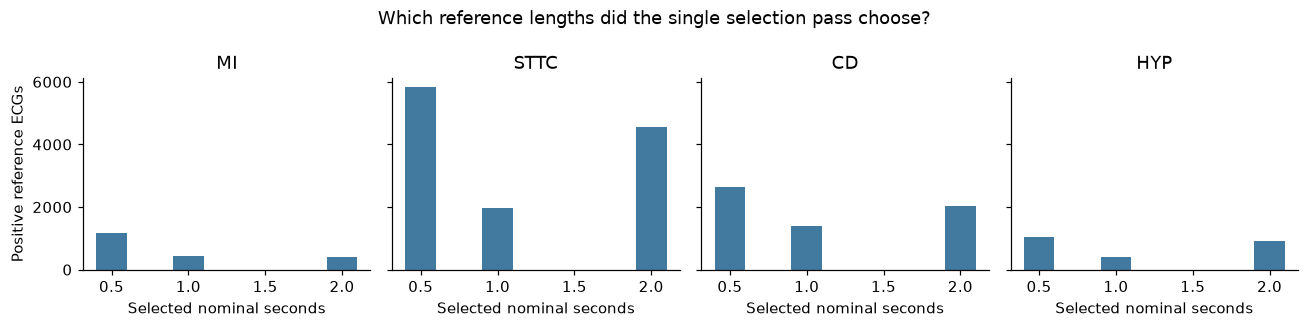

In [5]:
from ecg_experiment.condition_keys import spans

display(pd.DataFrame([
    {'proposal': 'Variable', 'candidates per ECG': len(spans()), 'lengths in seconds': '0.5, 1, 2'},
    {'proposal': 'Fixed', 'candidates per ECG': len(spans(True)), 'lengths in seconds': '1'},
]))
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, group in zip(axes, groups):
    hist = result['selections']['window_selected_keys']['support_positive'][group]['lengths']
    ax.bar([float(k) * 0.25 for k in hist], list(hist.values()), width=0.2, color='#427a9f')
    ax.set(title=group, xlabel='Selected nominal seconds')
axes[0].set_ylabel('Positive reference ECGs')
fig.suptitle('Which reference lengths did the single selection pass choose?')
plt.tight_layout()
plt.show()

## 6. Primary prediction results

For each group, every other SPH evaluation ECG counts as a negative, including recordings with
other abnormal groups. This evaluates whether the key distinguishes the requested group rather
than only separating abnormal ECGs from normal ones. Missing or imperfect annotations limit that
interpretation. AUROC measures ranking, with 0.5 indicating chance ranking; average precision (AP)
also depends on the group's prevalence. Neither metric sets a clinical referral threshold.

The primary endpoint is the unweighted mean of the four AUROCs. The frozen contrast is selected
region keys minus whole-record keys. Its interval uses 2,000 paired whole-patient bootstrap draws,
seed 20261103. The same patients are sampled for all groups and both arms. It holds the support
cohort, learned keys and pretrained encoder fixed.

,macro AUROC,macro AP
arm,,
Whole-record keys,0.8961,0.4178
"Region search, whole-record keys",0.8873,0.4114
Selected-region keys,0.7740,0.2593
Fixed 1-second region keys,0.8193,0.2948
Permuted condition keys,0.7025,0.1561


,difference,ci_low,ci_high,draws,skipped_draws,seed
0,-0.122072,-0.133550,-0.111008,2000,0,20261103


Frozen decision gates: {'gain_at_least_0.01': False, 'lower_95_above_zero': False, 'at_least_fixed_window_point': False, 'advance': False, 'pipeline_promoted': False}


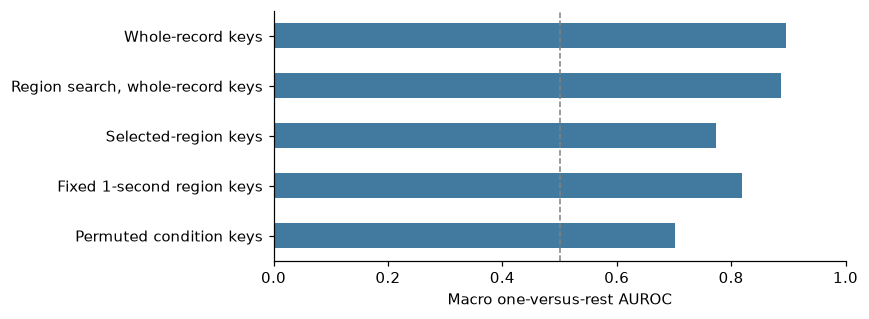

In [6]:
summary = pd.DataFrame([
    {'arm': names[arm], 'macro AUROC': result['metrics'][arm]['macro_auroc'],
     'macro AP': result['metrics'][arm]['macro_average_precision']}
    for arm in arms
]).set_index('arm')
display(summary.style.format('{:.4f}'))
primary = result['primary']
display(pd.DataFrame([primary]).style.format(precision=6))
print('Frozen decision gates:', result['decision'])
fig, ax = plt.subplots(figsize=(8, 3))
summary['macro AUROC'].iloc[::-1].plot.barh(ax=ax, color='#427a9f')
ax.set(xlim=(0, 1), xlabel='Macro one-versus-rest AUROC', ylabel='')
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

arm,Fixed 1-second region keys,Permuted condition keys,"Region search, whole-record keys",Selected-region keys,Whole-record keys
group,,,,,
CD,0.7845,0.6681,0.8271,0.7362,0.8409
HYP,0.8169,0.6616,0.8931,0.7806,0.8956
MI,0.8277,0.8061,0.9111,0.7516,0.9245
STTC,0.8481,0.6743,0.9178,0.8278,0.9234


arm,Fixed 1-second region keys,Permuted condition keys,"Region search, whole-record keys",Selected-region keys,Whole-record keys
group,,,,,
CD,0.3640,0.1794,0.4289,0.2860,0.4561
HYP,0.0928,0.0222,0.2225,0.0743,0.2047
MI,0.0654,0.0490,0.2032,0.0471,0.2149
STTC,0.6570,0.3739,0.7912,0.6298,0.7956


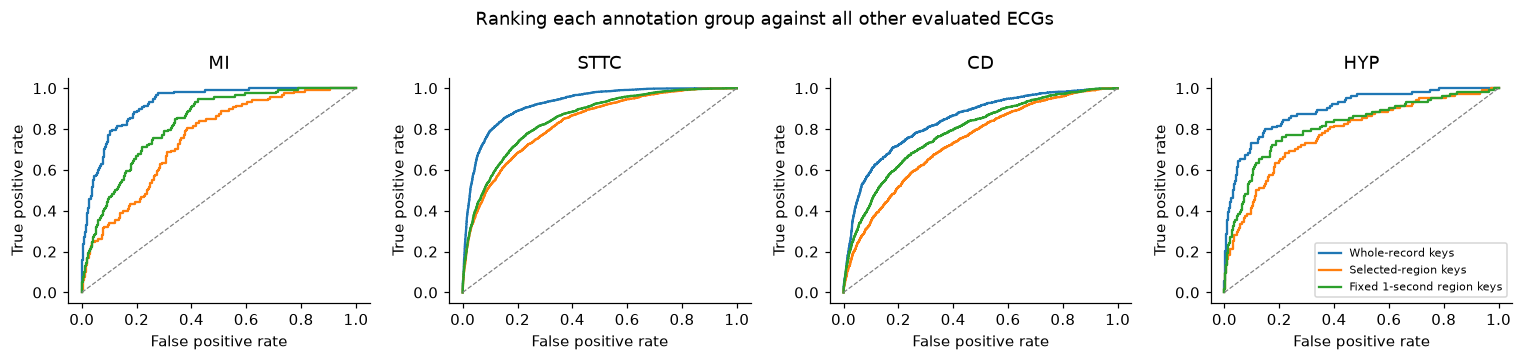

In [7]:
per_group = pd.DataFrame([
    {'group': group, 'arm': names[arm], **result['metrics'][arm]['groups'][group]}
    for group in groups for arm in arms
])
display(per_group.pivot(index='group', columns='arm', values='auroc').style.format('{:.4f}'))
display(per_group.pivot(index='group', columns='arm', values='average_precision').style.format('{:.4f}'))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for c, (ax, group) in enumerate(zip(axes, groups)):
    y = private['query_flags'][:, c]
    for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
        fpr, tpr, _ = roc_curve(y, private[f'score_{arm}'][:, c])
        ax.plot(fpr, tpr, label=names[arm])
    ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=0.8)
    ax.set(title=group, xlabel='False positive rate', ylabel='True positive rate')
axes[-1].legend(loc='lower right', fontsize=7)
fig.suptitle('Ranking each annotation group against all other evaluated ECGs')
plt.tight_layout()
plt.show()

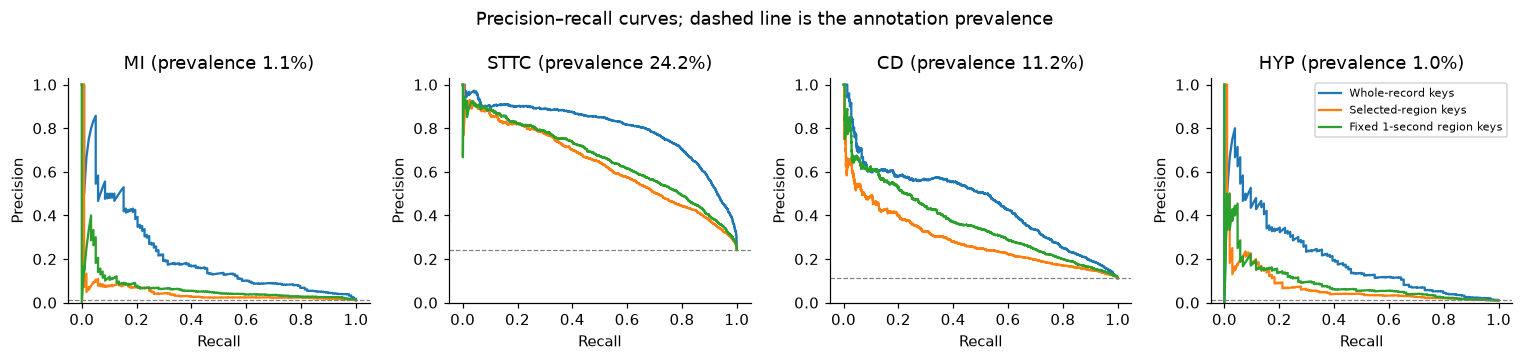

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for c, (ax, group) in enumerate(zip(axes, groups)):
    y = private['query_flags'][:, c]
    for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
        precision, recall, _ = precision_recall_curve(y, private[f'score_{arm}'][:, c])
        ax.plot(recall, precision, label=names[arm])
    ax.axhline(y.mean(), linestyle='--', color='gray', linewidth=0.8)
    ax.set(title=f'{group} (prevalence {y.mean():.1%})', xlabel='Recall', ylabel='Precision', ylim=(0, 1.03))
axes[-1].legend(fontsize=7)
fig.suptitle('Precision–recall curves; dashed line is the annotation prevalence')
plt.tight_layout()
plt.show()

## 7. Why the negative comparison matters

Condition-versus-normal discrimination is an easier, different task: other abnormalities are
removed from the negatives. The next table shows both definitions without substituting the
easier one for the primary endpoint. If performance is higher against normals, part of the
representation may reflect general abnormality rather than a specific annotation group.

In [9]:
negative_comparison = pd.DataFrame([
    {'group': group, 'comparison': task, 'AUROC': values[arm]['groups'][group]['auroc'],
     'AP': values[arm]['groups'][group]['average_precision']}
    for group in groups
    for task, values in [('All other ECGs', result['metrics']),
                         ('Normal ECGs only', result['condition_vs_normal'])]
    for arm in ['window_selected_keys']
])
comparison_table = negative_comparison.pivot(index='group', columns='comparison', values=['AUROC', 'AP'])
display(comparison_table.style.format('{:.4f}'))

## 8. Do the keys point in similar directions?

Cosine similarity between positive keys describes embedding geometry. High similarity can reflect
shared morphology, coexisting annotations, general abnormality or source effects. It is not a
measure of clinical equivalence or the probability that two diagnoses occur together.

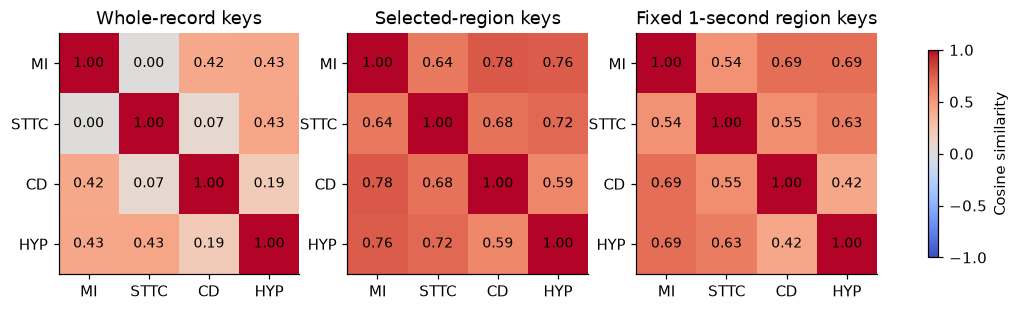

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, arm in zip(axes, ['whole', 'window_selected_keys', 'fixed_selected_keys']):
    values = np.asarray(result['positive_key_cosines'][arm])
    im = ax.imshow(values, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set(xticks=range(4), yticks=range(4), xticklabels=groups, yticklabels=groups, title=names[arm])
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{values[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=list(axes), shrink=0.7, label='Cosine similarity')
plt.show()

## 9. Descriptive clusters: fitting without condition labels

PCA is fitted on standardized, unit whole-record **training** embeddings (16 components).
K-means then partitions those training coordinates into five clusters, with ten initializations
and seed 20261103. SPH is projected and assigned to the frozen centers. Annotation memberships
do not enter PCA or k-means; they are used afterward to describe each cluster.

Five is a prespecified number of clusters, not a finding that five types of disease exist.
Cluster numbers have no clinical names. A cluster can contain normals, several conditions and
unannotated variation. We compare adjusted mutual information (AMI) with source family and the
exact combination of the four annotations. AMI is descriptive, adjusts for chance and depends on
the factors being compared; it does not prove removal of hospital effects or clinical validity.

First two PCA components explain 17.0% of training variance.
All sixteen explain 58.9%.


,Training cluster AMI
source_family,0.041888
annotation_combination,0.159981


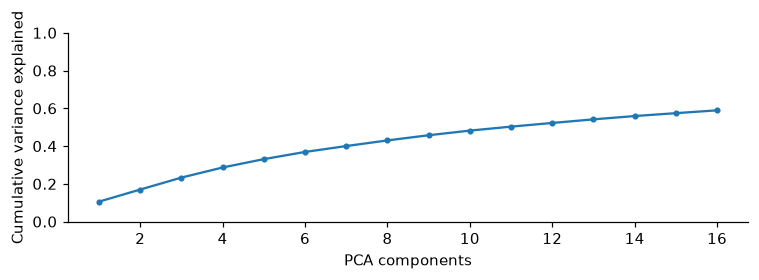

In [11]:
cluster = result['clusters']
variance = np.asarray(cluster['pca_explained_variance_ratio'])
print(f'First two PCA components explain {variance[:2].sum():.1%} of training variance.')
print(f'All sixteen explain {variance.sum():.1%}.')
display(pd.Series(cluster['training_ami'], name='Training cluster AMI').to_frame())
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(np.arange(1, 17), np.cumsum(variance), marker='o', markersize=3)
ax.set(xlabel='PCA components', ylabel='Cumulative variance explained', ylim=(0, 1))
plt.tight_layout()
plt.show()

,records,normal,MI,STTC,CD,HYP
Training cluster,,,,,,
0,4048,0,239,3349,1350,373
1,5030,2928,457,1043,638,377
2,5218,238,638,3466,2047,706
3,5862,3914,164,1200,523,304
4,4842,313,543,3298,1491,616


,records,normal,MI,STTC,CD,HYP
SPH cluster,,,,,,
0,210,0,6,179,48,23
1,4091,3026,39,639,415,14
2,1026,58,45,750,291,37
3,4153,3442,7,477,233,17
4,954,324,21,476,179,13


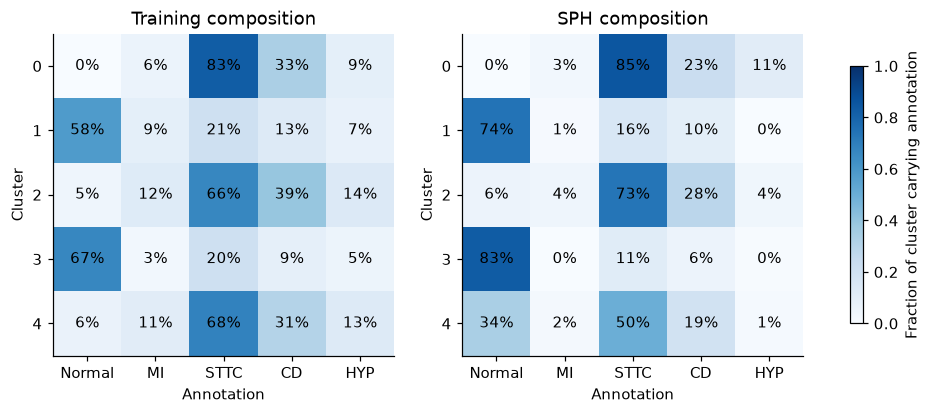

Group memberships overlap, so the annotation fractions need not add to 100%.


In [12]:
train_clusters = pd.DataFrame(cluster['training']).set_index('cluster')
query_clusters = pd.DataFrame(cluster['sph']).set_index('cluster')
display(train_clusters.rename_axis('Training cluster'))
display(query_clusters.rename_axis('SPH cluster'))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, table, title in zip(axes, [train_clusters, query_clusters],
                           ['Training composition', 'SPH composition']):
    prevalence = table[['normal', *groups]].div(table['records'], axis=0).fillna(0)
    im = ax.imshow(prevalence, vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(5), yticks=range(5), xticklabels=['Normal', *groups],
           yticklabels=range(5), xlabel='Annotation', ylabel='Cluster', title=title)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{prevalence.iloc[i, j]:.0%}', ha='center', va='center')
fig.colorbar(im, ax=list(axes), shrink=0.8, label='Fraction of cluster carrying annotation')
plt.show()
print('Group memberships overlap, so the annotation fractions need not add to 100%.')

,chapman_ningbo,cpsc,georgia,ptbxl
cluster,,,,
0,3338,57,204,449
1,1998,290,719,2023
2,2423,281,1242,1272
3,2599,231,839,2193
4,2644,337,970,891


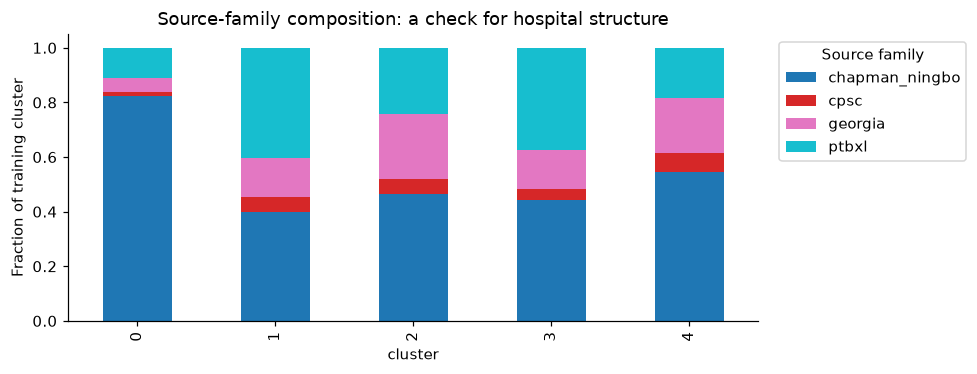

In [13]:
sources = pd.DataFrame(cluster['training_source_counts']).set_index('cluster')
display(sources)
sources.div(sources.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(9, 3.5), colormap='tab10')
plt.ylabel('Fraction of training cluster')
plt.title('Source-family composition: a check for hospital structure')
plt.legend(title='Source family', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 10. A two-dimensional view of SPH embeddings

The following charts are aggregated density grids, not individual patient scatter plots. All use
the same PCA axes fitted on training data. Each panel includes records carrying its annotation;
multiple-label records appear in more than one panel. For visual comparison, each panel's density
is normalized by its own record count, with a shared color scale. The grid bounds come from the
0.5th–99.5th training percentiles, and out-of-grid counts are reported. Two-dimensional overlap
does not establish overlap in all sixteen clustering dimensions, and apparent separation does
not establish useful classification accuracy.

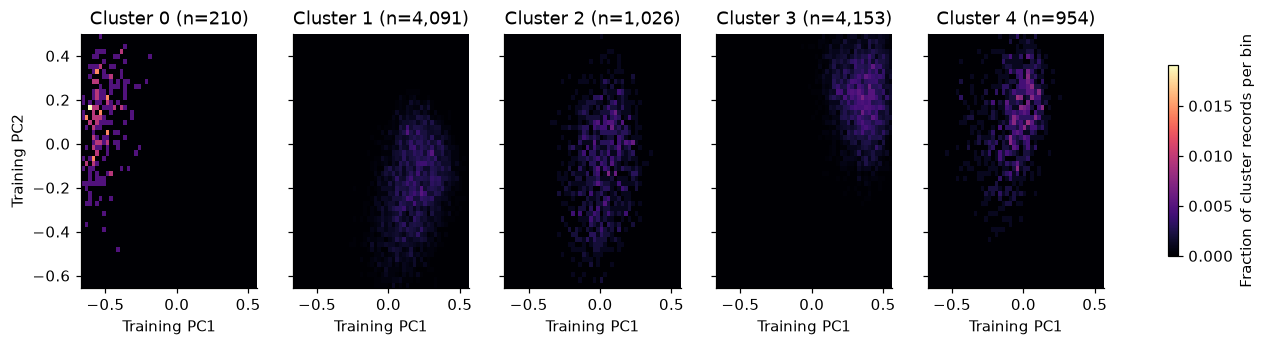

In [14]:
# Show the frozen cluster assignments on the same training-fitted PCA plane.
edges = [np.asarray(e) for e in cluster['grid_edges']]
coordinates = private['query_pca']
assigned = private['query_cluster']
cluster_grids = []
for k in range(5):
    keep = assigned == k
    grid, _, _ = np.histogram2d(coordinates[keep, 0], coordinates[keep, 1], bins=edges)
    cluster_grids.append(grid.T / keep.sum())
vmax = max(g.max() for g in cluster_grids)
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for k, (ax, grid) in enumerate(zip(axes, cluster_grids)):
    im = ax.pcolormesh(*edges, grid, vmin=0, vmax=vmax, cmap='magma', shading='auto')
    ax.set(title=f'Cluster {k} (n={(assigned == k).sum():,})', xlabel='Training PC1')
axes[0].set_ylabel('Training PC2')
fig.colorbar(im, ax=list(axes), shrink=0.75, label='Fraction of cluster records per bin')
plt.show()

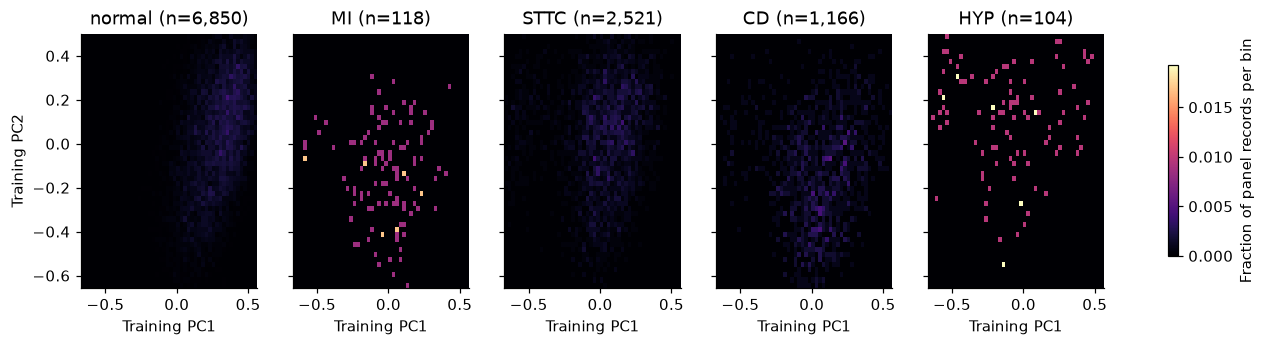

,records,outside_grid
normal,6850,125
MI,118,1
STTC,2521,26
CD,1166,10
HYP,104,1


In [15]:
panel_names = ['normal', *groups]
grids = cluster['sph_pca_grids']
xedges, yedges = [np.asarray(e) for e in cluster['grid_edges']]
densities = {g: np.asarray(grids[g]['counts']).T / grids[g]['records'] for g in panel_names}
vmax = max(a.max() for a in densities.values())
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for ax, group in zip(axes, panel_names):
    im = ax.pcolormesh(xedges, yedges, densities[group], cmap='magma', vmin=0, vmax=vmax, shading='auto')
    ax.set(title=f'{group} (n={grids[group]["records"]:,})', xlabel='Training PC1')
axes[0].set_ylabel('Training PC2')
fig.colorbar(im, ax=list(axes), shrink=0.75, label='Fraction of panel records per bin')
plt.show()
display(pd.DataFrame({g: {k: v for k, v in grids[g].items() if k != 'counts'} for g in panel_names}).T)

## 11. Arithmetic checks on the saved result

These checks reload the local private scores and recompute every per-group AUROC and AP,
including the condition-versus-normal task. They also check key geometry, region histograms
and cluster accounting. They do not refit keys or choose a new analysis after seeing results.
The saved patient-bootstrap interval and decision remain the prospectively specified comparison.

In [16]:
checks = 0
flags = private['query_flags']
for arm in arms:
    scores = private[f'score_{arm}']
    for c, group in enumerate(groups):
        for normal_only, container in [(False, result['metrics']), (True, result['condition_vs_normal'])]:
            keep = (flags[:, c] == 1) | ~flags.any(axis=1) if normal_only else np.ones(len(flags), bool)
            expected = container[arm]['groups'][group]
            assert roc_auc_score(flags[keep, c], scores[keep, c]) == expected['auroc']
            assert average_precision_score(flags[keep, c], scores[keep, c]) == expected['average_precision']
            checks += 2
for arm in ['whole', 'window_selected_keys', 'fixed_selected_keys']:
    key = private[f'{arm}_positive']
    np.testing.assert_array_equal(key @ key.T, np.asarray(result['positive_key_cosines'][arm]))
    checks += 1
assert sum(row['records'] for row in cluster['training']) == counts['training']
assert sum(row['records'] for row in cluster['sph']) == counts['query']
checks += 2
for arm in ['window_selected_keys', 'fixed_selected_keys']:
    for group in groups:
        selection = result['selections'][arm]['query_all'][group]
        assert sum(selection['starts']) == sum(selection['lengths'].values()) == counts['query']
        checks += 1
assert len(np.unique(private['query_patient'])) == counts['query_patients']
checks += 1
for prefix, rows in [('training', cluster['training']), ('query', cluster['sph'])]:
    local_flags = private['train_flags'] if prefix == 'training' else flags
    local_cluster = private[f'{prefix}_cluster']
    for row in rows:
        mask = local_cluster == row['cluster']
        assert int(mask.sum()) == row['records']
        assert int((~local_flags[mask].any(axis=1)).sum()) == row['normal']
        checks += 2
        for c, group in enumerate(groups):
            assert int(local_flags[mask, c].sum()) == row[group]
            checks += 1
print(f'{checks} saved-output arithmetic checks passed.')
verification = {
    'study': 'KEY-01', 'status': 'passed', 'checks': checks,
    'artifact_sha256': sha256_file(artifact_path), 'report_sha256': sha256_file(report_path),
    'refitted': False, 'raw_waveforms_read': False,
}
verification_path = ROOT / 'reports/condition-keys-2026-11-03/notebook-verification.json'
verification_path.write_text(json.dumps(verification, indent=2) + '\n')

154 saved-output arithmetic checks passed.


291

## 12. What this experiment establishes

The executed result below describes the fixed contrast, not a search for the best-looking arm.
Advancement requires a macro-AUROC gain of at least 0.01, a 95% lower bound above zero, and
a candidate point estimate at least as high as the fixed-window control. Cluster composition
and easier condition-versus-normal comparisons do not replace a failed primary gate.

This experiment measures recognition of four existing annotation groups on reused hospital
development ECGs. It does not test absent-reference diseases, physiological segmentation,
clinical diagnosis, university-student referral performance or an untouched final test. The interval
does not quantify uncertainty from resampling reference patients or retraining the encoder.
Project recommendations and follow-up priorities are recorded in the separate results report.

The selected-region versus whole-record macro-AUROC difference was
**-0.1221**, with a paired 95% interval
**[-0.1336, -0.1110]**. The selected-region candidate
did not pass all three frozen advancement gates. This is the prespecified result even when a
secondary control or an individual annotation group has a more favorable point estimate.

Per-group changes are descriptive and have no separate confirmatory intervals:

- MI: selected-region AUROC 0.7516, whole-record 0.9245; difference -0.1729.
- STTC: selected-region AUROC 0.8278, whole-record 0.9234; difference -0.0956.
- CD: selected-region AUROC 0.7362, whole-record 0.8409; difference -0.1047.
- HYP: selected-region AUROC 0.7806, whole-record 0.8956; difference -0.1151.

The cluster composition tables give these descriptive concentrations:

- MI is most concentrated in cluster 2: 4.4% of its 1,026 ECGs carry the annotation, against 1.1% across all SPH evaluation ECGs.
- STTC is most concentrated in cluster 0: 85.2% of its 210 ECGs carry the annotation, against 24.2% across all SPH evaluation ECGs.
- CD is most concentrated in cluster 2: 28.4% of its 1,026 ECGs carry the annotation, against 11.2% across all SPH evaluation ECGs.
- HYP is most concentrated in cluster 0: 11.0% of its 210 ECGs carry the annotation, against 1.0% across all SPH evaluation ECGs.

These are annotation enrichments, not cluster diagnoses. The same cluster may be most enriched for several groups, and a group's ECGs may span multiple clusters.

In [17]:
print(f'Selected-region macro AUROC: {summary.loc[names["window_selected_keys"], "macro AUROC"]:.6f}')
print(f'Whole-record macro AUROC: {summary.loc[names["whole"], "macro AUROC"]:.6f}')
print(f'Difference: {primary["difference"]:+.6f}; '
      f'95% interval [{primary["ci_low"]:+.6f}, {primary["ci_high"]:+.6f}]')
print('All frozen advancement gates passed:', result['decision']['advance'])
print('SAM executed:', result['sam_executed'])
print('Previously unsupported diseases evaluated:', result['unseen_disease_evaluated'])

Selected-region macro AUROC: 0.774030
Whole-record macro AUROC: 0.896102
Difference: -0.122072; 95% interval [-0.133550, -0.111008]
All frozen advancement gates passed: False
SAM executed: False
Previously unsupported diseases evaluated: False


## Reproduction and AI assistance

The full scientific run is `uv run --no-sync python -m scripts.experiments.run_condition_keys_v2`.
It requires the local, hash-bound caches and refuses to overwrite its output directory. The
notebook builder is `uv run --no-sync python -m scripts.reports.build_condition_keys_notebook`.
The notebook replays the completed outputs; it does not repeat encoder extraction or training.
See `docs/condition-keys-protocol-2026-11-03.md` and
`docs/condition-keys-results-2026-11-03.md` for the frozen design and results report.

OpenAI Codex assisted in developing the protocol, Python implementation, analysis and explanatory
text. Numerical results were computed locally from the project's existing artifacts. No external
model inference was used on ECG data in KEY-01. Private per-record arrays remain local; the
notebook displays aggregate tables, curves and density grids. The project authors remain
responsible for reviewing the interpretation and its clinical scope.